
# Modélisation RH sans data leakage

Objectif métier : prédire les employés susceptibles de quitter l'entreprise.

Ce notebook applique une procédure propre :

1. construction du DataFrame central à partir des trois fichiers sources ;
2. création de la cible `y` ;
3. création de `X_brut`, sans encodage ni imputation ;
4. séparation train / jeu caché de test 20 % ;
5. preprocessing appris uniquement sur `X_train_brut` ;
6. entraînement de trois modèles :
   - DummyClassifier ;
   - LogisticRegression ;
   - RandomForestClassifier ;
7. évaluation finale sur le jeu caché de 20 %.

Point clé : le jeu de test caché n'est jamais utilisé pour apprendre les transformations.


## 1. Imports

In [164]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


## 2. Chargement des fichiers sources

In [165]:

# Adapter les chemins si nécessaire
chemin_sirh = "extrait_sirh(1).csv"
chemin_eval = "extrait_eval(1).csv"
chemin_sondage = "extrait_sondage(1).csv"

# Dans l'environnement ChatGPT, les fichiers sont dans /mnt/data.
# Dans VS Code, place les fichiers dans le même dossier que le notebook,
# ou modifie les chemins ci-dessus.
try:
    df_sirh = pd.read_csv(chemin_sirh)
    df_eval = pd.read_csv(chemin_eval)
    df_sondage = pd.read_csv(chemin_sondage)
except FileNotFoundError:
    df_sirh = pd.read_csv("extrait_sirh.csv")
    df_eval = pd.read_csv("extrait_eval.csv")
    df_sondage = pd.read_csv("extrait_sondage.csv")

print("SIRH :", df_sirh.shape)
print("Évaluation :", df_eval.shape)
print("Sondage :", df_sondage.shape)


SIRH : (1470, 12)
Évaluation : (1470, 10)
Sondage : (1470, 12)


## 3. Construction du DataFrame central

In [166]:

def construire_dataframe_central(df_sirh, df_eval, df_sondage):
    """
    Construit le DataFrame central à partir des trois fichiers sources.
    La jointure est faite sur l'identifiant employé.
    """

    df_sirh = df_sirh.copy()
    df_eval = df_eval.copy()
    df_sondage = df_sondage.copy()

    # Création de l'identifiant employé depuis eval_number, ex : E_1 -> 1
    df_eval["id_employee"] = (
        df_eval["eval_number"]
        .astype(str)
        .str.extract(r"(\d+)")
        .astype(int)
    )

    # Renommage de la clé du fichier sondage
    df_sondage = df_sondage.rename(columns={"code_sondage": "id_employee"})

    df_central = (
        df_sirh
        .merge(df_eval, on="id_employee", how="inner", validate="one_to_one")
        .merge(df_sondage, on="id_employee", how="inner", validate="one_to_one")
    )

    return df_central


df_central = construire_dataframe_central(df_sirh, df_eval, df_sondage)

print("DataFrame central :", df_central.shape)
display(df_central.head())


DataFrame central : (1470, 33)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,2,3,2,4,1,1,E_1,3,Oui,11 %,Oui,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,3,2,2,2,4,3,E_2,4,Non,23 %,Non,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,4,2,1,3,2,3,E_4,3,Oui,15 %,Oui,0,3,1,2,2,Autre,Y,Occasionnel,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,4,3,1,3,3,3,E_5,3,Oui,11 %,Non,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,1,3,1,2,4,3,E_7,3,Non,12 %,Non,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2


## 4. Vérification des colonnes constantes du DataFrame central

In [167]:

colonnes_constantes_central = [
    col for col in df_central.columns
    if df_central[col].nunique(dropna=False) <= 1
]

print("Colonnes constantes dans le dataset central :")
print(colonnes_constantes_central)

for col in colonnes_constantes_central:
    print(f"{col} -> valeur unique : {df_central[col].iloc[0]}")


Colonnes constantes dans le dataset central :
['nombre_heures_travailless', 'nombre_employee_sous_responsabilite', 'ayant_enfants']
nombre_heures_travailless -> valeur unique : 80
nombre_employee_sous_responsabilite -> valeur unique : 1
ayant_enfants -> valeur unique : Y



## 5. Création de la cible `y`

La cible métier est :

- `0` : l'employé ne quitte pas l'entreprise ;
- `1` : l'employé quitte l'entreprise.

Le modèle apprend à repérer les profils associés à la classe `1`.


In [168]:

df = df_central.copy()

y = df["a_quitte_l_entreprise"].map({
    "Non": 0,
    "Oui": 1
})

print("Distribution de la cible :")
display(y.value_counts().rename("effectif").to_frame())

print("Distribution en pourcentage :")
display((y.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())


Distribution de la cible :


,effectif
a_quitte_l_entreprise,
0,1233
1,237


Distribution en pourcentage :


,pourcentage
a_quitte_l_entreprise,
0,83.88
1,16.12



## 6. Feature engineering ligne par ligne

Ces transformations ne créent pas de fuite de données, car elles utilisent uniquement les valeurs de la ligne courante.

En revanche, les transformations qui apprennent des statistiques globales comme l'imputation, l'encodage ou la suppression des colonnes constantes seront faites plus tard dans un pipeline sklearn, après le split.


In [169]:

def ajouter_features_metier(df):
    """
    Ajoute des variables métier calculées ligne par ligne.
    Ces variables ne dépendent pas de statistiques globales du dataset.
    """

    df = df.copy()
    eps = np.finfo(float).eps

    # Conversion du pourcentage d'augmentation en variable numérique
    df["augmentation_salaire_precedente_pct"] = (
        df["augementation_salaire_precedente"]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.strip()
        .astype(float)
    )

    # Ratios métier
    df["ratio_anciennete_experience"] = (
        df["annees_dans_l_entreprise"] / (df["annee_experience_totale"] + eps)
    )

    df["ratio_temps_poste_anciennete"] = (
        df["annees_dans_le_poste_actuel"] / (df["annees_dans_l_entreprise"] + eps)
    )

    df["ratio_promotion_anciennete"] = (
        df["annees_depuis_la_derniere_promotion"] / (df["annees_dans_l_entreprise"] + eps)
    )

    df["revenu_par_annee_experience"] = (
        df["revenu_mensuel"] / (df["annee_experience_totale"] + eps)
    )

    return df


df = ajouter_features_metier(df)



## 7. Création de `X_brut`

`X_brut` contient les variables explicatives avant encodage.

On supprime :

- la cible ;
- les identifiants techniques ;
- la version texte brute de l'augmentation de salaire, remplacée par `augmentation_salaire_precedente_pct`.


In [170]:

colonnes_a_supprimer = [
    "a_quitte_l_entreprise",
    "id_employee",
    "eval_number",
    "augementation_salaire_precedente"
]

X_brut = df.drop(columns=colonnes_a_supprimer, errors="ignore")

print("Dimensions X_brut :", X_brut.shape)
print("Dimensions y :", y.shape)
display(X_brut.head())


Dimensions X_brut : (1470, 34)
Dimensions y : (1470,)


,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,augmentation_salaire_precedente_pct,ratio_anciennete_experience,ratio_temps_poste_anciennete,ratio_promotion_anciennete,revenu_par_annee_experience
0,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,2,3,2,4,1,1,3,Oui,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5,11.0,0.750000,0.666667,0.000,749.125000
1,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,3,2,2,2,4,3,4,Non,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7,23.0,1.000000,0.700000,0.100,513.000000
2,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,4,2,1,3,2,3,3,Oui,0,3,1,2,2,Autre,Y,Occasionnel,0,0,15.0,0.000000,0.000000,0.000,298.571429
3,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,4,3,1,3,3,3,3,Oui,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0,11.0,1.000000,0.875000,0.375,363.625000
4,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,1,3,1,2,4,3,3,Non,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2,12.0,0.333333,1.000000,1.000,578.000000



## 8. Liste modifiable des features brutes

Pour retirer une variable du modèle, ajoute son nom dans `features_a_retirer`.

Important : cette sélection se fait avant le split et uniquement sur les noms de colonnes, pas sur les performances ou les statistiques du jeu complet.


In [171]:

features_a_utiliser = [
    "age",
    "genre",
    "revenu_mensuel",
    "statut_marital",
    "departement",
    "poste",
    "nombre_experiences_precedentes",
    "nombre_heures_travailless",
    "annee_experience_totale",
    "annees_dans_l_entreprise",
    "annees_dans_le_poste_actuel",
    "satisfaction_employee_environnement",
    "note_evaluation_precedente",
    "niveau_hierarchique_poste",
    "satisfaction_employee_nature_travail",
    "satisfaction_employee_equipe",
    "satisfaction_employee_equilibre_pro_perso",
    "note_evaluation_actuelle",
    "heure_supplementaires",
    "nombre_participation_pee",
    "nb_formations_suivies",
    "nombre_employee_sous_responsabilite",
    "distance_domicile_travail",
    "niveau_education",
    "domaine_etude",
    "ayant_enfants",
    "frequence_deplacement",
    "annees_depuis_la_derniere_promotion",
    "annes_sous_responsable_actuel",
    "augmentation_salaire_precedente_pct",
    "ratio_anciennete_experience",
    "ratio_temps_poste_anciennete",
    "ratio_promotion_anciennete",
    "revenu_par_annee_experience",
]

# Ajoute ici les variables à retirer si nécessaire.
features_a_retirer = [
    # "genre",
    # "revenu_mensuel",
    # "nombre_heures_travailless",
]

features_a_utiliser = [
    feature for feature in features_a_utiliser
    if feature not in features_a_retirer
]

features_absentes = [
    feature for feature in features_a_utiliser
    if feature not in X_brut.columns
]

if features_absentes:
    raise ValueError(f"Features absentes de X_brut : {features_absentes}")

X_brut = X_brut[features_a_utiliser].copy()

print("Nombre de features brutes utilisées avant encodage :", len(features_a_utiliser))
display(pd.DataFrame({
    "numero": range(1, len(features_a_utiliser) + 1),
    "feature_brute": features_a_utiliser
}))


Nombre de features brutes utilisées avant encodage : 34


,numero,feature_brute
0,1,age
1,2,genre
2,3,revenu_mensuel
3,4,statut_marital
4,5,departement
5,6,poste
6,7,nombre_experiences_precedentes
7,8,nombre_heures_travailless
8,9,annee_experience_totale
9,10,annees_dans_l_entreprise



## 9. Séparation train / jeu caché de test 20 %

La séparation est faite ici, avant toute imputation, encodage ou suppression de colonnes constantes.

- `X_train_brut`, `y_train` : utilisés pour apprendre ;
- `X_test_cache`, `y_test_cache` : jeu caché de 20 %, utilisé uniquement pour l'évaluation finale.

La stratification conserve la proportion d'employés ayant quitté l'entreprise dans le train et le test.


In [172]:

X_train_brut, X_test_cache, y_train, y_test_cache = train_test_split(
    X_brut,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train_brut :", X_train_brut.shape)
print("X_test_cache :", X_test_cache.shape)
print("y_train :", y_train.shape)
print("y_test_cache :", y_test_cache.shape)

print("\nDistribution cible - dataset complet :")
display((y.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())

print("\nDistribution cible - train :")
display((y_train.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())

print("\nDistribution cible - test caché :")
display((y_test_cache.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())


X_train_brut : (1176, 34)
X_test_cache : (294, 34)
y_train : (1176,)
y_test_cache : (294,)

Distribution cible - dataset complet :


,pourcentage
a_quitte_l_entreprise,
0,83.88
1,16.12



Distribution cible - train :


,pourcentage
a_quitte_l_entreprise,
0,83.84
1,16.16



Distribution cible - test caché :


,pourcentage
a_quitte_l_entreprise,
0,84.01
1,15.99



## 10. Détection des colonnes numériques et catégorielles sur le train uniquement

On détecte les types de colonnes à partir de `X_train_brut`, pas à partir du dataset complet.


In [173]:

colonnes_numeriques = X_train_brut.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

colonnes_categorielles = X_train_brut.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Nombre de colonnes numériques :", len(colonnes_numeriques))
print(colonnes_numeriques)

print("\nNombre de colonnes catégorielles :", len(colonnes_categorielles))
print(colonnes_categorielles)


Nombre de colonnes numériques : 26
['age', 'revenu_mensuel', 'nombre_experiences_precedentes', 'nombre_heures_travailless', 'annee_experience_totale', 'annees_dans_l_entreprise', 'annees_dans_le_poste_actuel', 'satisfaction_employee_environnement', 'note_evaluation_precedente', 'niveau_hierarchique_poste', 'satisfaction_employee_nature_travail', 'satisfaction_employee_equipe', 'satisfaction_employee_equilibre_pro_perso', 'note_evaluation_actuelle', 'nombre_participation_pee', 'nb_formations_suivies', 'nombre_employee_sous_responsabilite', 'distance_domicile_travail', 'niveau_education', 'annees_depuis_la_derniere_promotion', 'annes_sous_responsable_actuel', 'augmentation_salaire_precedente_pct', 'ratio_anciennete_experience', 'ratio_temps_poste_anciennete', 'ratio_promotion_anciennete', 'revenu_par_annee_experience']

Nombre de colonnes catégorielles : 8
['genre', 'statut_marital', 'departement', 'poste', 'heure_supplementaires', 'domaine_etude', 'ayant_enfants', 'frequence_deplacement

C:\Users\johnd\AppData\Local\Temp\ipykernel_33776\1928941944.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colonnes_categorielles = X_train_brut.select_dtypes(



## 11. Préprocessing sklearn sans data leakage

Le `ColumnTransformer` est intégré dans chaque pipeline.

Quand on appelle `pipeline.fit(X_train_brut, y_train)`, les étapes suivantes sont apprises uniquement sur le train :

- médiane des colonnes numériques ;
- modalité la plus fréquente des colonnes catégorielles ;
- modalités du OneHotEncoder ;
- suppression des colonnes à variance nulle avec `VarianceThreshold`.

Le jeu caché de test est uniquement transformé avec ces règles déjà apprises.


In [174]:

def creer_one_hot_encoder():
    """
    Crée un OneHotEncoder compatible avec différentes versions de sklearn.
    sklearn récent : sparse_output=False
    sklearn plus ancien : sparse=False
    """
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=False
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse=False
        )


preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerique",
            SimpleImputer(strategy="median"),
            colonnes_numeriques
        ),
        (
            "categoriel",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", creer_one_hot_encoder())
            ]),
            colonnes_categorielles
        )
    ],
    remainder="drop"
)


## 12. Définition des trois modèles

In [175]:

modeles = {
    "DummyClassifier": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("variance_threshold", VarianceThreshold(threshold=0.0)),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),

    "LogisticRegression": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("variance_threshold", VarianceThreshold(threshold=0.0)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "RandomForestClassifier": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("variance_threshold", VarianceThreshold(threshold=0.0)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            class_weight="balanced",
            min_samples_leaf=10,
            random_state=42
        ))
    ])
}

modeles


{'DummyClassifier': Pipeline(steps=[('preprocessing',
                  ColumnTransformer(transformers=[('numerique',
                                                   SimpleImputer(strategy='median'),
                                                   ['age', 'revenu_mensuel',
                                                    'nombre_experiences_precedentes',
                                                    'nombre_heures_travailless',
                                                    'annee_experience_totale',
                                                    'annees_dans_l_entreprise',
                                                    'annees_dans_le_poste_actuel',
                                                    'satisfaction_employee_environnement',
                                                    'note_evaluation_precedente',
                                                    'niv...
                                                                    SimpleImpu


## 13. Entraînement des modèles

Seul le jeu d'apprentissage est utilisé dans `fit()`.


In [176]:

modeles_entraines = {}

for nom_modele, pipeline in modeles.items():
    pipeline.fit(X_train_brut, y_train)
    modeles_entraines[nom_modele] = pipeline
    print(f"{nom_modele} entraîné sur le jeu d'apprentissage.")


DummyClassifier entraîné sur le jeu d'apprentissage.


LogisticRegression entraîné sur le jeu d'apprentissage.
RandomForestClassifier entraîné sur le jeu d'apprentissage.



## 14. Récupération des features après preprocessing

Cette cellule permet de connaître les features réellement envoyées au modèle après imputation, encodage one-hot et suppression des colonnes constantes.

La liste est récupérée à partir d'un pipeline déjà entraîné sur le train.


In [177]:

def recuperer_noms_features_pipeline(pipeline):
    """
    Récupère les noms des features après preprocessing et VarianceThreshold.
    Compatible avec les pipelines définis dans ce notebook.
    """

    preprocessor_fitted = pipeline.named_steps["preprocessing"]
    variance_fitted = pipeline.named_steps["variance_threshold"]

    noms_features = preprocessor_fitted.get_feature_names_out()
    masque_variance = variance_fitted.get_support()

    noms_features_conservees = noms_features[masque_variance]

    return pd.DataFrame({
        "numero": range(1, len(noms_features_conservees) + 1),
        "feature_apres_preprocessing": noms_features_conservees
    })


liste_features_finales = recuperer_noms_features_pipeline(
    modeles_entraines["RandomForestClassifier"]
)

print("Nombre de features finales après preprocessing :", len(liste_features_finales))
display(liste_features_finales)


Nombre de features finales après preprocessing : 45


,numero,feature_apres_preprocessing
0,1,numerique__age
1,2,numerique__revenu_mensuel
2,3,numerique__nombre_experiences_precedentes
3,4,numerique__annee_experience_totale
4,5,numerique__annees_dans_l_entreprise
5,6,numerique__annees_dans_le_poste_actuel
6,7,numerique__satisfaction_employee_environnement
7,8,numerique__note_evaluation_precedente
8,9,numerique__niveau_hierarchique_poste
9,10,numerique__satisfaction_employee_nature_travail



## 15. Évaluation sur le jeu caché de 20 %

Cette section évalue les modèles sur `X_test_cache` et `y_test_cache`.

Le jeu caché n'a pas été utilisé dans `fit()`.


In [178]:

def evaluer_modeles_sur_jeu_cache(modeles_entraines, X_test_cache, y_test_cache):
    """
    Calcule les métriques finales sur le jeu caché de test.
    """

    resultats = []

    for nom_modele, modele in modeles_entraines.items():
        y_pred = modele.predict(X_test_cache)

        if hasattr(modele, "predict_proba"):
            y_score = modele.predict_proba(X_test_cache)[:, 1]
            roc_auc = roc_auc_score(y_test_cache, y_score)
        else:
            roc_auc = np.nan

        resultats.append({
            "modele": nom_modele,
            "accuracy": accuracy_score(y_test_cache, y_pred),
            "precision": precision_score(y_test_cache, y_pred, zero_division=0),
            "recall": recall_score(y_test_cache, y_pred, zero_division=0),
            "f1_score": f1_score(y_test_cache, y_pred, zero_division=0),
            "roc_auc": roc_auc
        })

    return pd.DataFrame(resultats)


df_metriques_test_cache = evaluer_modeles_sur_jeu_cache(
    modeles_entraines=modeles_entraines,
    X_test_cache=X_test_cache,
    y_test_cache=y_test_cache
)

display(df_metriques_test_cache.round(3))


,modele,accuracy,precision,recall,f1_score,roc_auc
0,DummyClassifier,0.840,0.000,0.000,0.000,0.500
1,LogisticRegression,0.769,0.373,0.660,0.477,0.803
2,RandomForestClassifier,0.820,0.455,0.638,0.531,0.781



## 16. Diagnostic optionnel train vs test

Cette cellule ne sert pas à "tester" le modèle sur le train.

Elle sert uniquement à diagnostiquer un éventuel surapprentissage en comparant les scores d'apprentissage aux scores du jeu caché.

L'interprétation finale doit rester basée sur le jeu caché de 20 %.


In [179]:

def evaluer_train_et_test_cache(modeles_entraines, X_train_brut, y_train, X_test_cache, y_test_cache):
    """
    Calcule les métriques train et test caché.
    Les métriques train sont uniquement un diagnostic d'overfitting.
    """

    resultats = []

    for nom_modele, modele in modeles_entraines.items():
        for nom_jeu, X_data, y_true in [
            ("train_diagnostic", X_train_brut, y_train),
            ("test_cache_20pct", X_test_cache, y_test_cache)
        ]:
            y_pred = modele.predict(X_data)

            if hasattr(modele, "predict_proba"):
                y_score = modele.predict_proba(X_data)[:, 1]
                roc_auc = roc_auc_score(y_true, y_score)
            else:
                roc_auc = np.nan

            resultats.append({
                "modele": nom_modele,
                "jeu": nom_jeu,
                "accuracy": accuracy_score(y_true, y_pred),
                "precision": precision_score(y_true, y_pred, zero_division=0),
                "recall": recall_score(y_true, y_pred, zero_division=0),
                "f1_score": f1_score(y_true, y_pred, zero_division=0),
                "roc_auc": roc_auc
            })

    return pd.DataFrame(resultats)


df_metriques_train_test = evaluer_train_et_test_cache(
    modeles_entraines=modeles_entraines,
    X_train_brut=X_train_brut,
    y_train=y_train,
    X_test_cache=X_test_cache,
    y_test_cache=y_test_cache
)

display(df_metriques_train_test.round(3))


,modele,jeu,accuracy,precision,recall,f1_score,roc_auc
0,DummyClassifier,train_diagnostic,0.838,0.000,0.000,0.000,0.500
1,DummyClassifier,test_cache_20pct,0.840,0.000,0.000,0.000,0.500
2,LogisticRegression,train_diagnostic,0.784,0.412,0.789,0.542,0.881
3,LogisticRegression,test_cache_20pct,0.769,0.373,0.660,0.477,0.803
4,RandomForestClassifier,train_diagnostic,0.864,0.565,0.689,0.621,0.879
5,RandomForestClassifier,test_cache_20pct,0.820,0.455,0.638,0.531,0.781


## 17. Classification reports sur le jeu caché

In [180]:

for nom_modele, modele in modeles_entraines.items():
    print("=" * 80)
    print(nom_modele)
    print("=" * 80)

    y_pred_cache = modele.predict(X_test_cache)

    print(classification_report(
        y_test_cache,
        y_pred_cache,
        target_names=[
            "Ne quitte pas l'entreprise",
            "Quitte l'entreprise"
        ],
        zero_division=0
    ))


DummyClassifier
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.84      1.00      0.91       247
       Quitte l'entreprise       0.00      0.00      0.00        47

                  accuracy                           0.84       294
                 macro avg       0.42      0.50      0.46       294
              weighted avg       0.71      0.84      0.77       294

LogisticRegression
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.92      0.79      0.85       247
       Quitte l'entreprise       0.37      0.66      0.48        47

                  accuracy                           0.77       294
                 macro avg       0.65      0.72      0.66       294
              weighted avg       0.84      0.77      0.79       294

RandomForestClassifier
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.93      0.85    

## 18. Matrices de confusion contextualisées

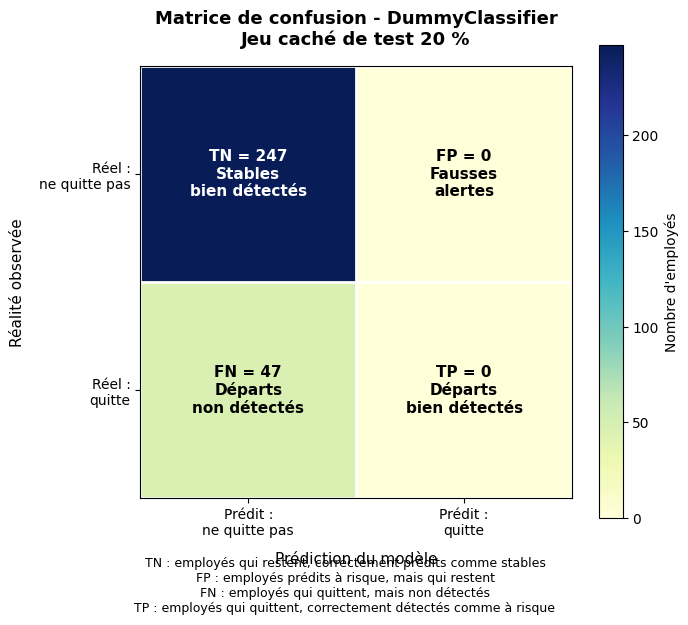

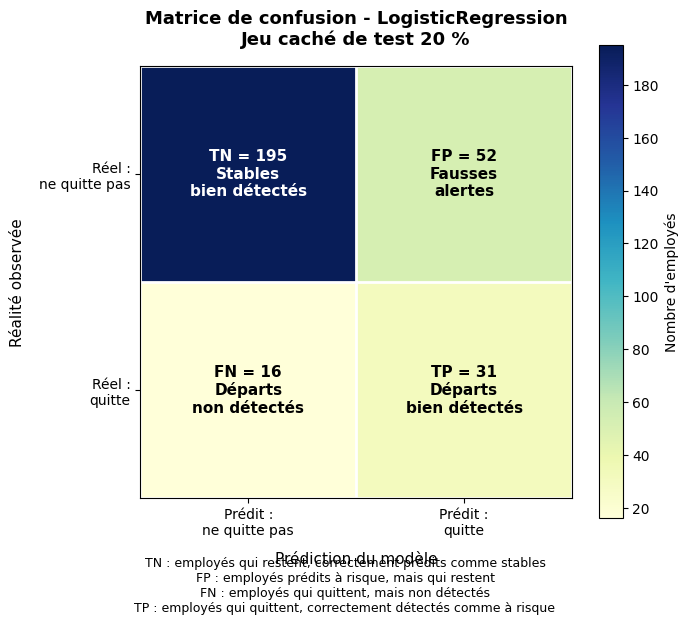

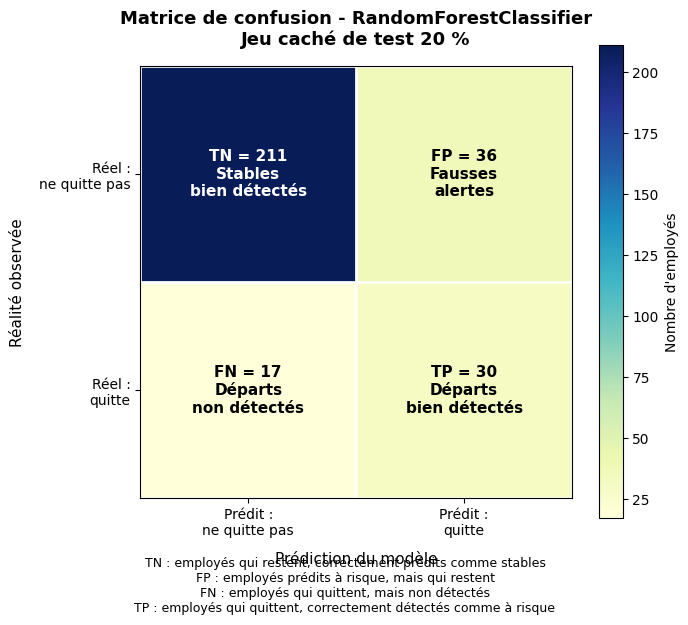

In [181]:

def afficher_matrice_confusion_rh_lisible(y_true, y_pred, nom_modele):
    """
    Affiche une matrice de confusion lisible pour le contexte RH.

    Classe 0 : l'employé ne quitte pas l'entreprise.
    Classe 1 : l'employé quitte l'entreprise.
    """

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    annotations = np.array([
        [
            f"TN = {tn}\nStables\nbien détectés",
            f"FP = {fp}\nFausses\nalertes"
        ],
        [
            f"FN = {fn}\nDéparts\nnon détectés",
            f"TP = {tp}\nDéparts\nbien détectés"
        ]
    ])

    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, cmap="YlGnBu")

    cbar = plt.colorbar(image, ax=ax)
    cbar.set_label("Nombre d'employés", fontsize=10)

    ax.set_title(
        f"Matrice de confusion - {nom_modele}\nJeu caché de test 20 %",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Prédiction du modèle", fontsize=11, labelpad=10)
    ax.set_ylabel("Réalité observée", fontsize=11, labelpad=10)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels([
        "Prédit :\nne quitte pas",
        "Prédit :\nquitte"
    ], fontsize=10)

    ax.set_yticklabels([
        "Réel :\nne quitte pas",
        "Réel :\nquitte"
    ], fontsize=10)

    max_value = cm.max()

    for i in range(2):
        for j in range(2):
            valeur = cm[i, j]
            couleur_texte = "white" if valeur > max_value / 2 else "black"

            ax.text(
                j,
                i,
                annotations[i, j],
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=couleur_texte
            )

    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=2)
    ax.tick_params(which="minor", bottom=False, left=False)

    texte_legende = (
        "TN : employés qui restent, correctement prédits comme stables\n"
        "FP : employés prédits à risque, mais qui restent\n"
        "FN : employés qui quittent, mais non détectés\n"
        "TP : employés qui quittent, correctement détectés comme à risque"
    )

    fig.text(
        0.5,
        -0.04,
        texte_legende,
        ha="center",
        fontsize=9
    )

    plt.tight_layout()
    plt.show()


for nom_modele, modele in modeles_entraines.items():
    y_pred_cache = modele.predict(X_test_cache)
    afficher_matrice_confusion_rh_lisible(
        y_true=y_test_cache,
        y_pred=y_pred_cache,
        nom_modele=nom_modele
    )


## 19. Graphique comparatif des métriques sur le jeu caché

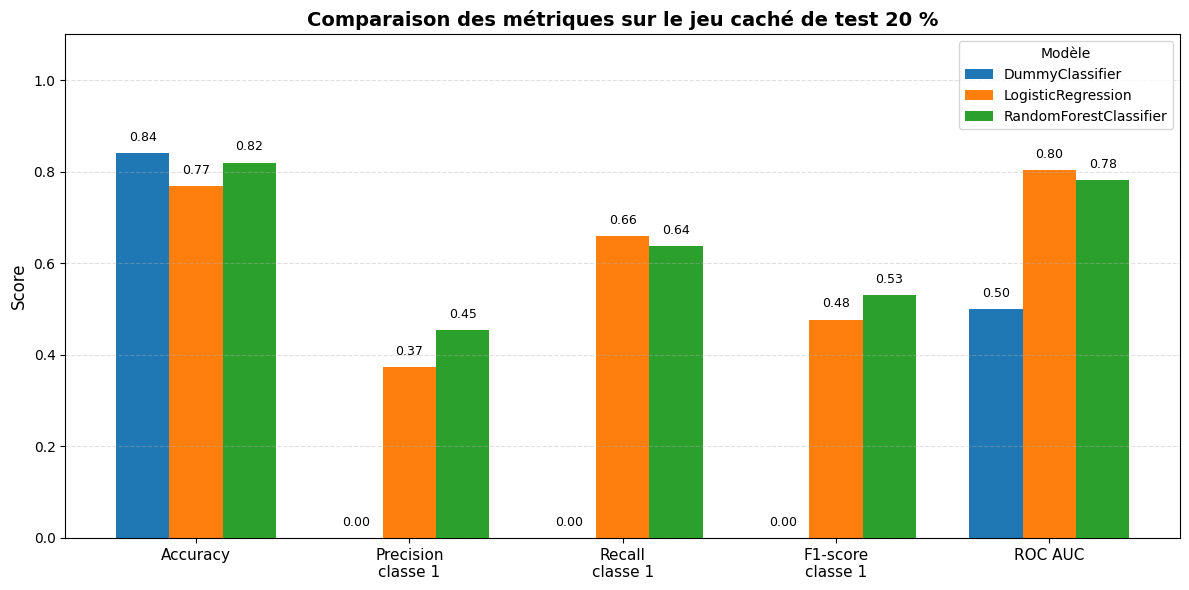

In [182]:

def graphique_metriques_jeu_cache(df_metriques_test_cache):
    """
    Visualise les métriques finales des modèles sur le jeu caché de 20 %.
    """

    metriques = [
        "accuracy",
        "precision",
        "recall",
        "f1_score",
        "roc_auc"
    ]

    labels_metriques = [
        "Accuracy",
        "Precision\nclasse 1",
        "Recall\nclasse 1",
        "F1-score\nclasse 1",
        "ROC AUC"
    ]

    modeles = df_metriques_test_cache["modele"].tolist()

    x = np.arange(len(metriques))
    largeur_barre = 0.25

    fig, ax = plt.subplots(figsize=(12, 6))

    for i, modele in enumerate(modeles):
        valeurs = (
            df_metriques_test_cache
            .loc[df_metriques_test_cache["modele"] == modele, metriques]
            .values
            .flatten()
        )

        ax.bar(
            x + i * largeur_barre,
            valeurs,
            width=largeur_barre,
            label=modele
        )

        for j, valeur in enumerate(valeurs):
            ax.text(
                x[j] + i * largeur_barre,
                valeur + 0.02,
                f"{valeur:.2f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_title(
        "Comparaison des métriques sur le jeu caché de test 20 %",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel("Score", fontsize=12)
    ax.set_ylim(0, 1.1)

    ax.set_xticks(x + largeur_barre)
    ax.set_xticklabels(labels_metriques, fontsize=11)

    ax.legend(title="Modèle")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


graphique_metriques_jeu_cache(df_metriques_test_cache)


## 20. Graphique spécifique aux métriques RH importantes

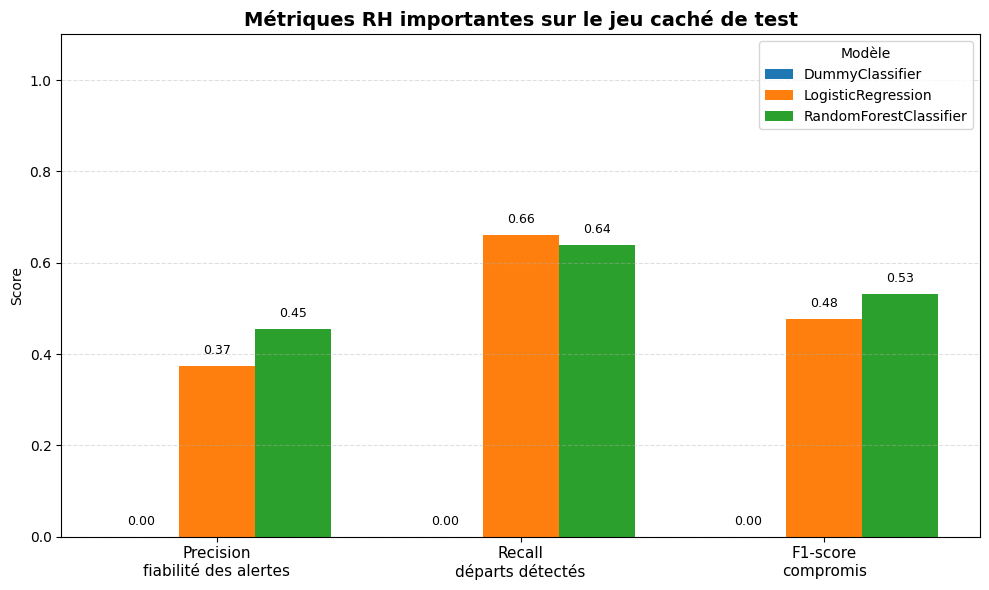

In [183]:

def graphique_metriques_rh_importantes(df_metriques_test_cache):
    """
    Visualise les métriques les plus utiles pour le contexte RH :
    precision, recall et f1-score de la classe positive.
    """

    metriques = [
        "precision",
        "recall",
        "f1_score"
    ]

    labels_metriques = [
        "Precision\nfiabilité des alertes",
        "Recall\ndéparts détectés",
        "F1-score\ncompromis"
    ]

    modeles = df_metriques_test_cache["modele"].tolist()

    x = np.arange(len(metriques))
    largeur_barre = 0.25

    fig, ax = plt.subplots(figsize=(10, 6))

    for i, modele in enumerate(modeles):
        valeurs = (
            df_metriques_test_cache
            .loc[df_metriques_test_cache["modele"] == modele, metriques]
            .values
            .flatten()
        )

        ax.bar(
            x + i * largeur_barre,
            valeurs,
            width=largeur_barre,
            label=modele
        )

        for j, valeur in enumerate(valeurs):
            ax.text(
                x[j] + i * largeur_barre,
                valeur + 0.02,
                f"{valeur:.2f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_title(
        "Métriques RH importantes sur le jeu caché de test",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.1)

    ax.set_xticks(x + largeur_barre)
    ax.set_xticklabels(labels_metriques, fontsize=11)

    ax.legend(title="Modèle")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


graphique_metriques_rh_importantes(df_metriques_test_cache)



## 21. Export des résultats

Les fichiers exportés peuvent être utilisés pour documenter les résultats du projet.


In [184]:

df_metriques_test_cache.to_csv("metriques_jeu_cache_20pct_sans_leakage.csv", index=False)
df_metriques_train_test.to_csv("metriques_train_test_diagnostic_sans_leakage.csv", index=False)
liste_features_finales.to_csv("features_finales_apres_preprocessing_sans_leakage.csv", index=False)

print("Exports terminés.")


Exports terminés.



## 22. Interprétation à adapter selon les scores obtenus

À rédiger après exécution du notebook :

- le DummyClassifier sert de modèle de référence ;
- la régression logistique est le modèle linéaire ;
- la Random Forest est le modèle non-linéaire ;
- l'interprétation finale doit être basée sur les scores du jeu caché de 20 % ;
- le recall de la classe 1 mesure la capacité à détecter les employés qui quittent ;
- la precision de la classe 1 mesure la fiabilité des alertes RH ;
- le F1-score mesure le compromis entre precision et recall ;
- le ROC AUC mesure la capacité du modèle à classer les employés selon leur niveau de risque.


In [185]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score
)

import pandas as pd
import numpy as np

In [186]:
# Scorer F5 : privilégie fortement le recall
f5_scorer = make_scorer(
    fbeta_score,
    beta=5,
    zero_division=0
)

In [187]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1_score": make_scorer(f1_score, zero_division=0),
    "f5_score": f5_scorer,
    "roc_auc": "roc_auc"
}

In [188]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [189]:
resultats_cv = []

for nom_modele, pipeline in modeles.items():
    
    print(f"Cross-validation en cours : {nom_modele}")
    
    scores = cross_validate(
        estimator=pipeline,
        X=X_train_brut,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )
    
    for i in range(cv.get_n_splits()):
        resultats_cv.append({
            "modele": nom_modele,
            "fold": i + 1,
            
            "train_accuracy": scores["train_accuracy"][i],
            "train_precision": scores["train_precision"][i],
            "train_recall": scores["train_recall"][i],
            "train_f1_score": scores["train_f1_score"][i],
            "train_f5_score": scores["train_f5_score"][i],
            "train_roc_auc": scores["train_roc_auc"][i],
            
            "val_accuracy": scores["test_accuracy"][i],
            "val_precision": scores["test_precision"][i],
            "val_recall": scores["test_recall"][i],
            "val_f1_score": scores["test_f1_score"][i],
            "val_f5_score": scores["test_f5_score"][i],
            "val_roc_auc": scores["test_roc_auc"][i],
        })

df_cv_detail = pd.DataFrame(resultats_cv)

display(df_cv_detail.round(3))

Cross-validation en cours : DummyClassifier
Cross-validation en cours : LogisticRegression
Cross-validation en cours : RandomForestClassifier


,modele,fold,train_accuracy,train_precision,train_recall,train_f1_score,train_f5_score,train_roc_auc,val_accuracy,val_precision,val_recall,val_f1_score,val_f5_score,val_roc_auc
0,DummyClassifier,1,0.838,0.000,0.000,0.000,0.000,0.500,0.839,0.000,0.000,0.000,0.000,0.500
1,DummyClassifier,2,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
2,DummyClassifier,3,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
3,DummyClassifier,4,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
4,DummyClassifier,5,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
5,LogisticRegression,1,0.791,0.423,0.789,0.550,0.764,0.891,0.809,0.439,0.658,0.526,0.645,0.807
6,LogisticRegression,2,0.800,0.436,0.809,0.567,0.783,0.894,0.757,0.349,0.579,0.436,0.565,0.785
7,LogisticRegression,3,0.791,0.424,0.829,0.561,0.800,0.881,0.749,0.370,0.789,0.504,0.757,0.861
8,LogisticRegression,4,0.768,0.393,0.796,0.526,0.766,0.876,0.774,0.397,0.763,0.523,0.737,0.876
9,LogisticRegression,5,0.792,0.423,0.789,0.550,0.764,0.890,0.745,0.359,0.737,0.483,0.708,0.827


In [190]:
df_cv_synthese = (
    df_cv_detail
    .groupby("modele")
    .agg(
        accuracy_cv=("val_accuracy", "mean"),
        precision_cv=("val_precision", "mean"),
        recall_cv=("val_recall", "mean"),
        f1_score_cv=("val_f1_score", "mean"),
        f5_score_cv=("val_f5_score", "mean"),
        roc_auc_cv=("val_roc_auc", "mean"),
        f5_score_std=("val_f5_score", "std")
    )
    .reset_index()
    .sort_values(by="f5_score_cv", ascending=False)
)

display(df_cv_synthese.round(3))

,modele,accuracy_cv,precision_cv,recall_cv,f1_score_cv,f5_score_cv,roc_auc_cv,f5_score_std
1,LogisticRegression,0.767,0.383,0.705,0.494,0.682,0.831,0.078
2,RandomForestClassifier,0.823,0.461,0.458,0.454,0.457,0.780,0.072
0,DummyClassifier,0.838,0.000,0.000,0.000,0.000,0.500,0.000


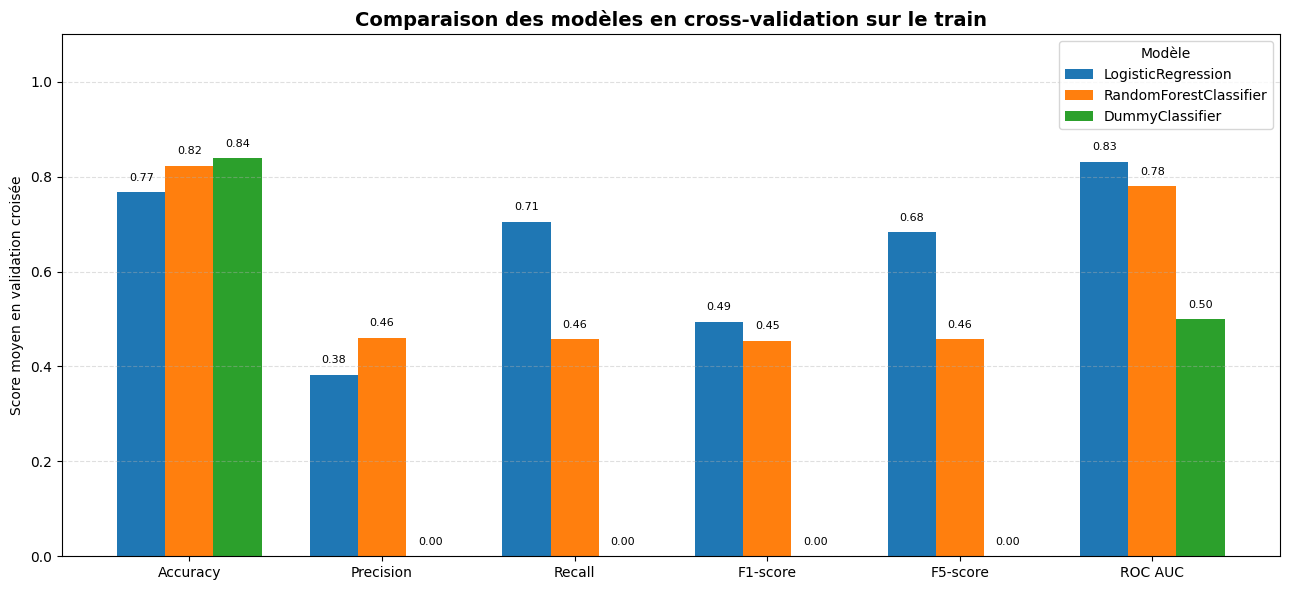

In [191]:
import matplotlib.pyplot as plt

def graphique_cv_metriques(df_cv_synthese):
    """
    Compare les métriques moyennes de cross-validation
    pour les différents modèles.
    """
    
    metriques = [
        "accuracy_cv",
        "precision_cv",
        "recall_cv",
        "f1_score_cv",
        "f5_score_cv",
        "roc_auc_cv"
    ]
    
    labels_metriques = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "F5-score",
        "ROC AUC"
    ]
    
    modeles_liste = df_cv_synthese["modele"].tolist()
    
    x = np.arange(len(metriques))
    largeur_barre = 0.25
    
    fig, ax = plt.subplots(figsize=(13, 6))
    
    for i, modele in enumerate(modeles_liste):
        valeurs = (
            df_cv_synthese
            .loc[df_cv_synthese["modele"] == modele, metriques]
            .values
            .flatten()
        )
        
        ax.bar(
            x + i * largeur_barre,
            valeurs,
            width=largeur_barre,
            label=modele
        )
        
        for j, valeur in enumerate(valeurs):
            ax.text(
                x[j] + i * largeur_barre,
                valeur + 0.02,
                f"{valeur:.2f}",
                ha="center",
                va="bottom",
                fontsize=8
            )
    
    ax.set_title(
        "Comparaison des modèles en cross-validation sur le train",
        fontsize=14,
        fontweight="bold"
    )
    
    ax.set_ylabel("Score moyen en validation croisée")
    ax.set_ylim(0, 1.1)
    
    ax.set_xticks(x + largeur_barre)
    ax.set_xticklabels(labels_metriques)
    
    ax.legend(title="Modèle")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    
    plt.tight_layout()
    plt.show()


graphique_cv_metriques(df_cv_synthese)

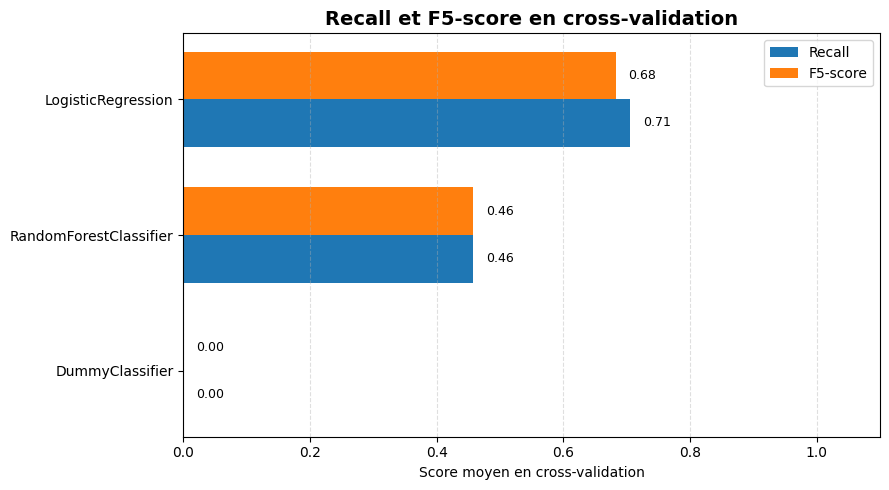

In [192]:
def graphique_cv_recall_f5(df_cv_synthese):
    """
    Visualise uniquement le recall et le F5-score,
    les deux métriques les plus importantes si l'objectif
    est de détecter les employés susceptibles de quitter l'entreprise.
    """
    
    df_plot = df_cv_synthese.sort_values(by="f5_score_cv", ascending=True)
    
    y_pos = np.arange(len(df_plot))
    hauteur_barre = 0.35
    
    fig, ax = plt.subplots(figsize=(9, 5))
    
    ax.barh(
        y_pos - hauteur_barre / 2,
        df_plot["recall_cv"],
        height=hauteur_barre,
        label="Recall"
    )
    
    ax.barh(
        y_pos + hauteur_barre / 2,
        df_plot["f5_score_cv"],
        height=hauteur_barre,
        label="F5-score"
    )
    
    for i, valeur in enumerate(df_plot["recall_cv"]):
        ax.text(
            valeur + 0.02,
            i - hauteur_barre / 2,
            f"{valeur:.2f}",
            va="center",
            fontsize=9
        )
    
    for i, valeur in enumerate(df_plot["f5_score_cv"]):
        ax.text(
            valeur + 0.02,
            i + hauteur_barre / 2,
            f"{valeur:.2f}",
            va="center",
            fontsize=9
        )
    
    ax.set_title(
        "Recall et F5-score en cross-validation",
        fontsize=14,
        fontweight="bold"
    )
    
    ax.set_xlabel("Score moyen en cross-validation")
    ax.set_xlim(0, 1.1)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_plot["modele"])
    
    ax.legend()
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    
    plt.tight_layout()
    plt.show()


graphique_cv_recall_f5(df_cv_synthese)

In [193]:
meilleur_modele_cv = (
    df_cv_synthese
    .sort_values(by="f5_score_cv", ascending=False)
    .iloc[0]
)

print("Meilleur modèle selon le F5-score en cross-validation :")
print(meilleur_modele_cv["modele"])

print("\nScores moyens en cross-validation :")
print(meilleur_modele_cv)

Meilleur modèle selon le F5-score en cross-validation :
LogisticRegression

Scores moyens en cross-validation :
modele          LogisticRegression
accuracy_cv               0.766971
precision_cv              0.382882
recall_cv                 0.705263
f1_score_cv               0.494288
f5_score_cv               0.682381
roc_auc_cv                0.831027
f5_score_std              0.078061
Name: 1, dtype: object


In [194]:
nom_meilleur_modele = meilleur_modele_cv["modele"]

modele_final = modeles[nom_meilleur_modele]

modele_final.fit(X_train_brut, y_train)

print(f"Modèle final entraîné sur les 80 % du train : {nom_meilleur_modele}")

Modèle final entraîné sur les 80 % du train : LogisticRegression


In [195]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_cache = modele_final.predict(X_test_cache)

if hasattr(modele_final, "predict_proba"):
    y_score_cache = modele_final.predict_proba(X_test_cache)[:, 1]
    roc_auc_cache = roc_auc_score(y_test_cache, y_score_cache)
else:
    roc_auc_cache = np.nan

resultats_final_cache = {
    "modele": nom_meilleur_modele,
    "accuracy": accuracy_score(y_test_cache, y_pred_cache),
    "precision": precision_score(y_test_cache, y_pred_cache, zero_division=0),
    "recall": recall_score(y_test_cache, y_pred_cache, zero_division=0),
    "f1_score": f1_score(y_test_cache, y_pred_cache, zero_division=0),
    "f5_score": fbeta_score(y_test_cache, y_pred_cache, beta=5, zero_division=0),
    "roc_auc": roc_auc_cache
}

df_resultat_final_cache = pd.DataFrame([resultats_final_cache])

display(df_resultat_final_cache.round(3))

print(classification_report(
    y_test_cache,
    y_pred_cache,
    target_names=[
        "Ne quitte pas l'entreprise",
        "Quitte l'entreprise"
    ],
    zero_division=0
))

print("Matrice de confusion sur le jeu caché :")
print(confusion_matrix(y_test_cache, y_pred_cache, labels=[0, 1]))

,modele,accuracy,precision,recall,f1_score,f5_score,roc_auc
0,LogisticRegression,0.769,0.373,0.66,0.477,0.641,0.803


                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.92      0.79      0.85       247
       Quitte l'entreprise       0.37      0.66      0.48        47

                  accuracy                           0.77       294
                 macro avg       0.65      0.72      0.66       294
              weighted avg       0.84      0.77      0.79       294

Matrice de confusion sur le jeu caché :
[[195  52]
 [ 16  31]]


La régression logistique obtient de meilleurs résultats que l’arbre de décision sur certaines métriques, notamment le recall ou le F5-score.

Cela peut s’expliquer par le fait que le dataset est relativement petit et déséquilibré. L’arbre de décision peut facilement créer des règles trop spécifiques au jeu d’apprentissage, ce qui augmente le risque de surapprentissage.

La régression logistique, au contraire, apprend une relation plus globale entre les variables explicatives et la probabilité de départ. De plus, elle bénéficie d’une régularisation qui limite les coefficients trop extrêmes.

Dans ce projet RH, les variables encodées en one-hot, comme le poste, les heures supplémentaires, le statut marital ou la fréquence de déplacement, sont bien exploitées par un modèle linéaire. Cela peut expliquer pourquoi la régression logistique généralise mieux sur le jeu de validation ou le jeu caché.

In [196]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    make_scorer,
    fbeta_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

import pandas as pd
import numpy as np

In [197]:
f5_scorer = make_scorer(
    fbeta_score,
    beta=5,
    zero_division=0
)

In [198]:
pipeline_logistique = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("variance_threshold", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [199]:
param_grid_logistique = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
    "model__solver": ["lbfgs"],
    "model__penalty": ["l2"]
}

In [200]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [201]:
grid_logistique = GridSearchCV(
    estimator=pipeline_logistique,
    param_grid=param_grid_logistique,
    scoring=f5_scorer,
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_logistique.fit(X_train_brut, y_train)

i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced'], 'model__penalty': ['l2'], 'model__solver': ['lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messa

In [202]:
print("Meilleur score F5 en cross-validation :")
print(round(grid_logistique.best_score_, 3))

print("\nMeilleurs hyperparamètres :")
print(grid_logistique.best_params_)

Meilleur score F5 en cross-validation :
0.721

Meilleurs hyperparamètres :
{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs'}


In [203]:
df_grid_logistique = pd.DataFrame(grid_logistique.cv_results_)

colonnes_resultats = [
    "param_model__C",
    "param_model__class_weight",
    "param_model__solver",
    "param_model__penalty",
    "mean_train_score",
    "std_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

df_grid_logistique_resultats = (
    df_grid_logistique[colonnes_resultats]
    .sort_values(by="rank_test_score")
)

display(df_grid_logistique_resultats.round(3))

,param_model__C,param_model__class_weight,param_model__solver,param_model__penalty,mean_train_score,std_train_score,mean_test_score,std_test_score,rank_test_score
1,0.01,balanced,lbfgs,l2,0.777,0.008,0.721,0.074,1
3,0.10,balanced,lbfgs,l2,0.776,0.013,0.702,0.064,2
7,10.00,balanced,lbfgs,l2,0.777,0.010,0.682,0.071,3
9,100.00,balanced,lbfgs,l2,0.778,0.010,0.682,0.071,3
5,1.00,balanced,lbfgs,l2,0.775,0.014,0.682,0.070,5
6,10.00,NaN,lbfgs,l2,0.550,0.028,0.485,0.114,6
8,100.00,NaN,lbfgs,l2,0.550,0.028,0.485,0.114,7
4,1.00,NaN,lbfgs,l2,0.546,0.022,0.480,0.123,8
2,0.10,NaN,lbfgs,l2,0.486,0.026,0.450,0.116,9
0,0.01,NaN,lbfgs,l2,0.170,0.024,0.174,0.047,10


In [204]:
meilleur_modele_logistique = grid_logistique.best_estimator_

In [205]:
y_pred_cache = meilleur_modele_logistique.predict(X_test_cache)
y_score_cache = meilleur_modele_logistique.predict_proba(X_test_cache)[:, 1]

resultats_logistique_optimisee = {
    "modele": "LogisticRegression optimisée",
    "accuracy": accuracy_score(y_test_cache, y_pred_cache),
    "precision": precision_score(y_test_cache, y_pred_cache, zero_division=0),
    "recall": recall_score(y_test_cache, y_pred_cache, zero_division=0),
    "f1_score": f1_score(y_test_cache, y_pred_cache, zero_division=0),
    "f5_score": fbeta_score(y_test_cache, y_pred_cache, beta=5, zero_division=0),
    "roc_auc": roc_auc_score(y_test_cache, y_score_cache)
}

df_resultats_logistique_optimisee = pd.DataFrame([resultats_logistique_optimisee])

display(df_resultats_logistique_optimisee.round(3))

,modele,accuracy,precision,recall,f1_score,f5_score,roc_auc
0,LogisticRegression optimisée,0.779,0.39,0.681,0.496,0.662,0.825


In [206]:
print(classification_report(
    y_test_cache,
    y_pred_cache,
    target_names=[
        "Ne quitte pas l'entreprise",
        "Quitte l'entreprise"
    ],
    zero_division=0
))

                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.93      0.80      0.86       247
       Quitte l'entreprise       0.39      0.68      0.50        47

                  accuracy                           0.78       294
                 macro avg       0.66      0.74      0.68       294
              weighted avg       0.84      0.78      0.80       294



In [207]:
cm = confusion_matrix(y_test_cache, y_pred_cache, labels=[0, 1])

print("Matrice de confusion - Régression logistique optimisée")
print(cm)

Matrice de confusion - Régression logistique optimisée
[[197  50]
 [ 15  32]]


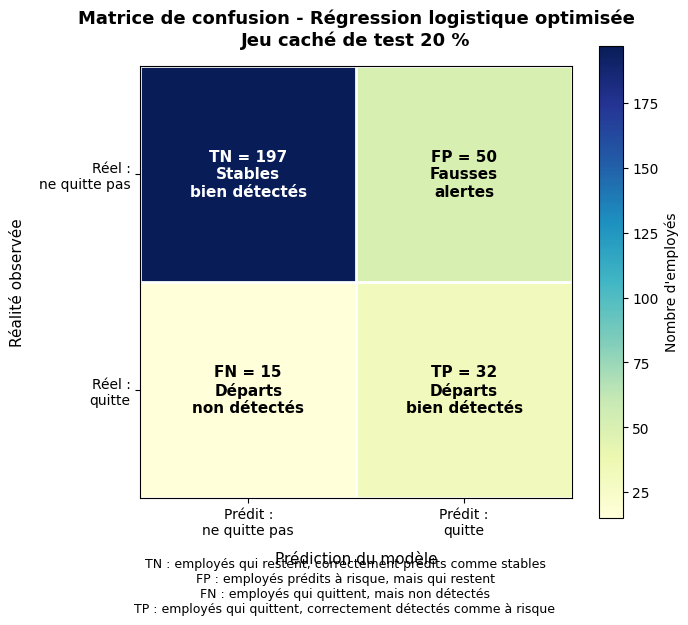

In [208]:
afficher_matrice_confusion_rh_lisible(
    y_true=y_test_cache,
    y_pred=y_pred_cache,
    nom_modele="Régression logistique optimisée"
)

Une recherche d'hyperparamètres a été réalisée avec GridSearchCV sur la régression logistique.

Cette recherche est effectuée uniquement sur le jeu d'apprentissage, représentant 80 % des données. Le jeu caché de test de 20 % n'est pas utilisé pendant cette étape.

Le critère d'optimisation choisi est le F5-score, car il donne davantage d'importance au recall. Ce choix est cohérent avec le contexte RH : l'objectif est de détecter un maximum d'employés susceptibles de quitter l'entreprise.

Après sélection des meilleurs hyperparamètres par validation croisée, le modèle optimisé est évalué une seule fois sur le jeu caché de test.